# EDA do dataset AI4I 2020 (Manutenção Preditiva)

**Projeto:** Protótipo de Manutenção Preditiva com Shapash
**Objetivo deste notebook:** dar ao grupo uma visão comum do dataset **antes** de qualquer modelagem: o que são as colunas, como os dados foram gerados, onde estão os problemas e quais armadilhas evitar.

**Como usar**
1. Execute tudo com **Ambiente de execução → Executar tudo** (leva cerca de 1 minuto).
2. Os dados são baixados automaticamente do repositório UCI. Se estiver sem internet, o notebook pede o upload do `ai4i2020.csv`.
3. Para mexer no notebook, faça **Arquivo → Salvar uma cópia no Drive**.

**Roteiro**
1. Carga e contexto do dataset
2. Qualidade dos dados
3. Análise univariada
4. Estrutura temporal (o `UDI` importa?)
5. A variável-alvo e o desbalanceamento
6. Os modos de falha
7. Variáveis derivadas e validação das regras físicas
8. Análise bivariada
9. Relações físicas em gráficos
10. Armadilhas para a modelagem
11. Conclusões e próximos passos

In [1]:
import io
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

SEED = 42
np.random.seed(SEED)

# Paleta (azul = referência / sem falha, laranja = falha)
AZUL, LARANJA = "#2a78d6", "#eb6834"
TEXTO, TEXTO2, MUDO, GRADE, SUPERFICIE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"

mpl.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TEXTO2, "axes.titlecolor": TEXTO,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUDO, "ytick.color": MUDO, "text.color": TEXTO,
    "legend.frameon": False, "font.size": 10,
})
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

print("pandas", pd.__version__, "| numpy", np.__version__, "| matplotlib", mpl.__version__, "| seaborn", sns.__version__)

pandas 3.0.5 | numpy 2.5.3 | matplotlib 3.11.2 | seaborn 0.13.2


## 1. Carga e contexto do dataset

O **AI4I 2020 Predictive Maintenance Dataset** (Stephan Matzka, 2020) está no repositório UCI. Ponto-chave: ele é **sintético**. Os dados foram gerados por um simulador que imita uma máquina de fresagem, com regras de falha conhecidas. Isso é ótimo para estudar interpretabilidade (sabemos a "resposta certa"), mas significa que **os resultados não se generalizam automaticamente para uma fábrica real**.

Fonte: <https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset>

In [2]:
UCI_ZIP = "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip"

def carregar_dados():
    """Ordem: arquivo local -> download do UCI -> upload manual (Colab)."""
    local = Path("ai4i2020.csv")
    if local.exists():
        return pd.read_csv(local, encoding="utf-8-sig"), "arquivo local (ai4i2020.csv)"
    try:
        with urllib.request.urlopen(UCI_ZIP, timeout=30) as r:
            z = zipfile.ZipFile(io.BytesIO(r.read()))
        nome = [n for n in z.namelist() if n.lower().endswith(".csv")][0]
        return pd.read_csv(z.open(nome), encoding="utf-8-sig"), "repositório UCI"
    except Exception as e:
        print("Download falhou:", e, "\nFaça o upload do ai4i2020.csv:")
        from google.colab import files
        up = files.upload()
        return pd.read_csv(io.BytesIO(next(iter(up.values()))), encoding="utf-8-sig"), "upload manual"

bruto, origem = carregar_dados()
print(f"Fonte: {origem} | {bruto.shape[0]} linhas x {bruto.shape[1]} colunas")

# Nomes curtos (mais fáceis de usar no código). As unidades ficam no dicionário LABELS.
RENAME = {
    "UDI": "udi", "Product ID": "product_id", "Type": "type",
    "Air temperature [K]": "air_temp", "Process temperature [K]": "process_temp",
    "Rotational speed [rpm]": "rpm", "Torque [Nm]": "torque", "Tool wear [min]": "tool_wear",
    "Machine failure": "machine_failure",
}
df = bruto.rename(columns=RENAME).copy()

NUM = ["air_temp", "process_temp", "rpm", "torque", "tool_wear"]
MODOS = ["TWF", "HDF", "PWF", "OSF", "RNF"]
LABELS = {
    "air_temp": "Temperatura do ar [K]", "process_temp": "Temperatura do processo [K]",
    "rpm": "Velocidade de rotação [rpm]", "torque": "Torque [Nm]", "tool_wear": "Desgaste da ferramenta [min]",
    "temp_diff": "ΔT = processo − ar [K]", "power_w": "Potência [W]", "wear_x_torque": "Desgaste × torque [min·Nm]",
}
df.head()

Fonte: arquivo local (ai4i2020.csv) | 10000 linhas x 14 colunas


,udi,product_id,type,air_temp,process_temp,rpm,torque,tool_wear,machine_failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


### Dicionário de variáveis

| Coluna (CSV) | Nome curto | Tipo | O que é | Papel na modelagem |
|---|---|---|---|---|
| `UDI` | `udi` | inteiro | Identificador sequencial (1 a 10000) | **Descartar** como feature (pode servir para ordenar no tempo) |
| `Product ID` | `product_id` | texto | Letra L/M/H + número de série | **Descartar** (identificador, 10000 valores únicos) |
| `Type` | `type` | categórica | Qualidade do produto: **L**ow, **M**edium, **H**igh | Feature categórica |
| `Air temperature [K]` | `air_temp` | contínua | Temperatura do ar (random walk, em torno de 300 K) | Feature |
| `Process temperature [K]` | `process_temp` | contínua | Temperatura do processo (≈ ar + 10 K) | Feature |
| `Rotational speed [rpm]` | `rpm` | contínua | Rotação (calculada a partir de uma potência de ~2860 W + ruído) | Feature |
| `Torque [Nm]` | `torque` | contínua | Torque (normal, média ≈ 40 Nm, σ ≈ 10 Nm) | Feature |
| `Tool wear [min]` | `tool_wear` | contínua | Minutos de desgaste acumulado da ferramenta | Feature |
| `Machine failure` | `machine_failure` | binária | **Alvo**: 1 se ao menos um modo de falha ocorreu | **Target** |
| `TWF`, `HDF`, `PWF`, `OSF`, `RNF` | idem | binárias | Os cinco modos de falha individuais | **Não usar como feature** (vazamento, veja a seção 10) |

**Os cinco modos de falha, em linguagem simples**

| Modo | Nome | Regra de geração |
|---|---|---|
| **TWF** | Tool Wear Failure | A ferramenta quebra/é trocada quando o desgaste atinge um valor sorteado entre 200 e 240 min |
| **HDF** | Heat Dissipation Failure | ΔT (processo − ar) < 8,6 K **e** rotação < 1380 rpm |
| **PWF** | Power Failure | Potência = torque × rotação (em rad/s) fora de 3500–9000 W |
| **OSF** | Overstrain Failure | Desgaste × torque acima de 11000 (L), 12000 (M) ou 13000 (H) min·Nm |
| **RNF** | Random Failure | 0,1% de chance de falha, independente de tudo |

## 2. Qualidade dos dados

Primeiro o básico: tamanho, tipos, nulos, duplicatas e identificadores.

In [3]:
print("Dimensões:", df.shape)
print("Valores nulos (total):", int(df.isna().sum().sum()))
print("Linhas duplicadas:", int(df.duplicated().sum()))
print("UDI único e crescente:", df.udi.is_unique and df.udi.is_monotonic_increasing)
print("Product ID únicos:", df.product_id.nunique(), "de", len(df))
print("Prefixo do Product ID == Type em todas as linhas:", bool((df.product_id.str[0] == df.type).all()))
print()
df.dtypes.to_frame("tipo").T

Dimensões: (10000, 14)
Valores nulos (total): 0
Linhas duplicadas: 0
UDI único e crescente: True
Product ID únicos: 10000 de 10000
Prefixo do Product ID == Type em todas as linhas: True



,udi,product_id,type,air_temp,process_temp,rpm,torque,tool_wear,machine_failure,TWF,HDF,PWF,OSF,RNF
tipo,int64,str,str,float64,float64,int64,float64,int64,int64,int64,int64,int64,int64,int64


In [4]:
def n_outliers(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

resumo = pd.DataFrame({
    "mínimo": df[NUM].min(), "mediana": df[NUM].median(), "média": df[NUM].mean().round(2),
    "máximo": df[NUM].max(), "desvio": df[NUM].std().round(2),
    "assimetria": df[NUM].skew().round(2), "outliers (IQR)": df[NUM].apply(n_outliers),
})
resumo.index = [LABELS[c] for c in resumo.index]
resumo

,mínimo,mediana,média,máximo,desvio,assimetria,outliers (IQR)
Temperatura do ar [K],295.3,300.1,300.00,304.5,2.00,0.11,0
Temperatura do processo [K],305.7,310.1,310.01,313.8,1.48,0.02,0
Velocidade de rotação [rpm],1168.0,1503.0,1538.78,2886.0,179.28,1.99,418
Torque [Nm],3.8,40.1,39.99,76.6,9.97,-0.01,69
Desgaste da ferramenta [min],0.0,108.0,107.95,253.0,63.65,0.03,0


**O que isso diz:** o dataset está **limpo**, sem nulos, duplicatas ou tipos errados. Isso é raro em dados reais, e é mais um sinal de que é sintético. Os "outliers" pela regra do IQR são esperados (os valores seguem distribuições normais ou quase normais) e **não** devem ser removidos às cegas: valores extremos de torque e rotação são justamente onde acontecem muitas falhas (veja a seção 9).

### Documento descritivo × CSV real

Ao comparar o texto descritivo com o CSV, encontramos **divergências**. Vale o grupo saber, para ninguém ficar procurando "o erro" no próprio código:

In [5]:
prop = df["type"].value_counts(normalize=True) * 100
comparativo = pd.DataFrame([
    ["Proporção de Type (L / M / H)", "50% / 30% / 20%", f"{prop['L']:.0f}% / {prop['M']:.0f}% / {prop['H']:.0f}%"],
    ["TWF (falhas por desgaste)", "51 falhas", int(df.TWF.sum())],
    ["HDF (dissipação de calor)", "115", int(df.HDF.sum())],
    ["PWF (potência)", "95", int(df.PWF.sum())],
    ["OSF (sobrecarga)", "98", int(df.OSF.sum())],
    ["RNF (aleatórias)", "5", int(df.RNF.sum())],
    ["Nº de colunas", "14 (mas o texto diz “6 features”)", df.shape[1]],
], columns=["Item", "Documento descritivo", "CSV real"])
comparativo

,Item,Documento descritivo,CSV real
0,Proporção de Type (L / M / H),50% / 30% / 20%,60% / 30% / 10%
1,TWF (falhas por desgaste),51 falhas,46
2,HDF (dissipação de calor),115,115
3,PWF (potência),95,95
4,OSF (sobrecarga),98,98
5,RNF (aleatórias),5,19
6,Nº de colunas,14 (mas o texto diz “6 features”),14


**Conclusão:** HDF, PWF e OSF batem exatamente. TWF e RNF **não**: o CSV tem menos TWF (46 contra 51) e bem mais RNF (19 contra 5) do que o texto afirma, e a proporção de Types é 60/30/10, não 50/30/20. **Confie no CSV, não no texto.** (Na seção 6 vemos que o RNF ainda esconde uma inconsistência maior.)

## 3. Análise univariada

Distribuição de cada variável isoladamente. A linha laranja marca a mediana.

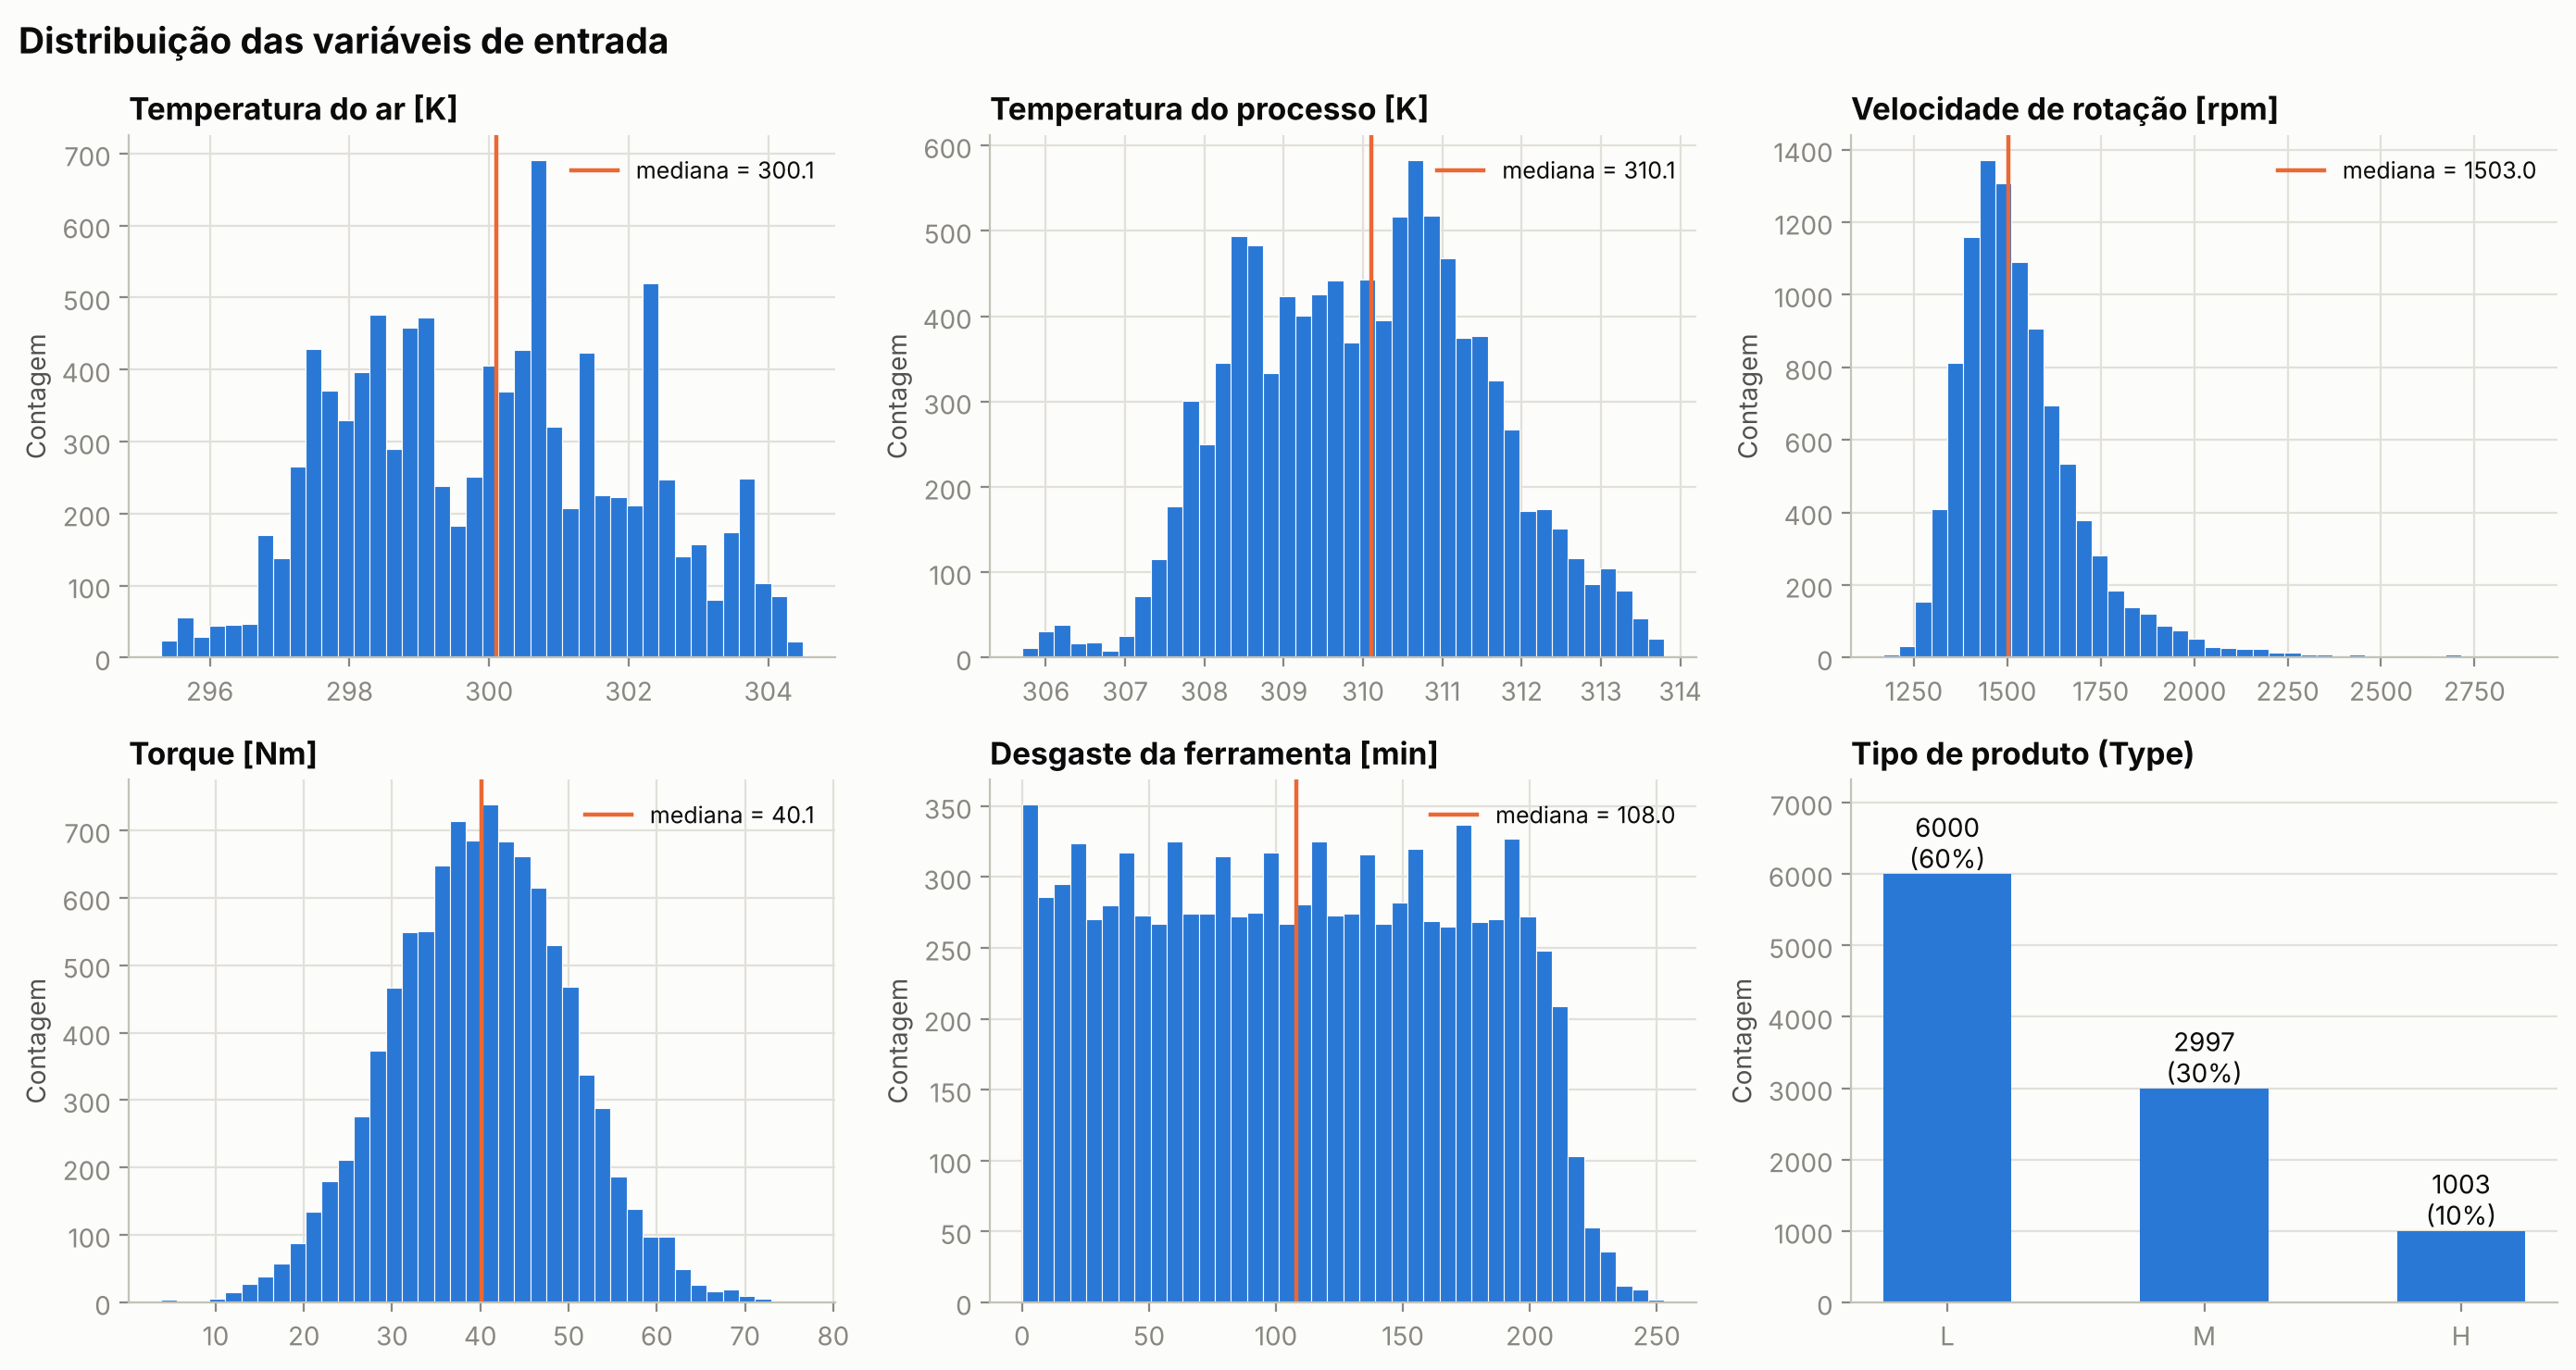

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, col in zip(axes.flat, NUM):
    ax.hist(df[col], bins=40, color=AZUL, edgecolor=SUPERFICIE, linewidth=0.4)
    med = df[col].median()
    ax.axvline(med, color=LARANJA, lw=1.6, label=f"mediana = {med:.1f}")
    ax.set_title(LABELS[col]); ax.set_ylabel("Contagem"); ax.legend(fontsize=9)

ax = axes.flat[5]
cont = df["type"].value_counts().reindex(["L", "M", "H"])
ax.bar(cont.index, cont.values, color=AZUL, width=0.5)
for x, v in zip(cont.index, cont.values):
    ax.text(x, v, f"{v}\n({v/len(df):.0%})", ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, cont.max() * 1.22); ax.set_title("Tipo de produto (Type)"); ax.set_ylabel("Contagem")
ax.grid(axis="x", visible=False)

fig.suptitle("Distribuição das variáveis de entrada", x=0.01, ha="left", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

**Leitura rápida**
- **Temperaturas do ar e do processo:** formato aproximadamente em sino, mas um pouco "irregular", consequência do random walk usado na geração (veja a seção 4).
- **Rotação:** **assimétrica à direita** (cauda longa). Apenas 32 linhas passam de 2500 rpm, e **26 delas têm falha**. Rotação alta significa torque baixo (a potência é quase constante).
- **Torque:** em sino, centrado em ~40 Nm.
- **Desgaste da ferramenta:** distribuição **quase uniforme até ~200 min**, com cauda mais rala até 253 min. É bem diferente das outras, porque a ferramenta acumula desgaste até ser trocada (veja a seção 4).
- **Type:** desbalanceado (60% L, 30% M, 10% H). Qualquer análise por tipo precisa lembrar que H tem poucos exemplos.

## 4. Estrutura temporal: o `UDI` importa?

O UCI classifica o dataset como "Time-Series". A documentação diz que as temperaturas foram geradas por **random walk** (cada valor é o anterior mais um pequeno passo). Se isso é verdade, linhas **vizinhas** deveriam ser parecidas. Vamos testar com a autocorrelação de lag 1 (correlação de cada linha com a anterior).

*Analogia:* a temperatura é como o nível de um rio, que não salta de 300 K para 304 K de uma linha para outra. Já a rotação e o torque são como lançar um dado a cada linha: não "lembram" do valor anterior.

,autocorrelação (lag 1)
Temperatura do ar [K],0.999
Temperatura do processo [K],0.999
Velocidade de rotação [rpm],0.008
Torque [Nm],0.005
Desgaste da ferramenta [min],0.931


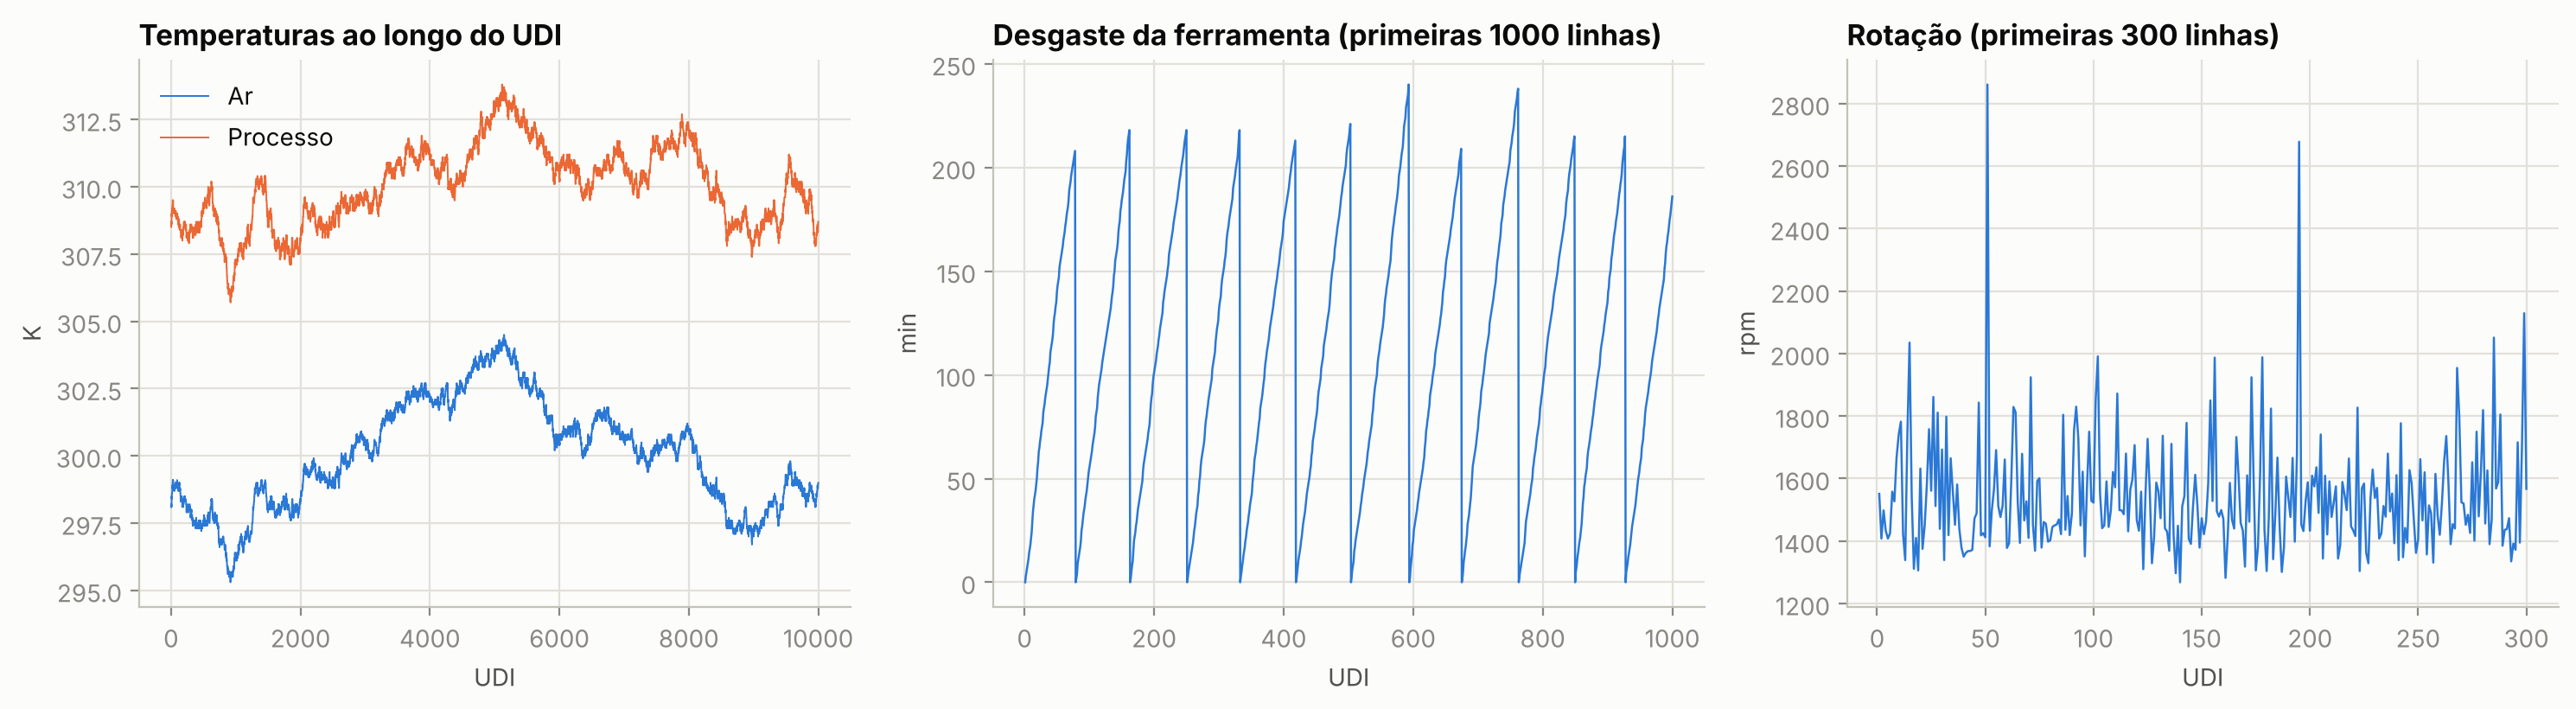

In [7]:
autocorr = df[NUM].apply(lambda s: s.autocorr(lag=1)).round(3)
autocorr.index = [LABELS[c] for c in autocorr.index]
display(autocorr.to_frame("autocorrelação (lag 1)"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
axes[0].plot(df.udi, df.air_temp, color=AZUL, lw=0.7, label="Ar")
axes[0].plot(df.udi, df.process_temp, color=LARANJA, lw=0.7, label="Processo")
axes[0].set_title("Temperaturas ao longo do UDI"); axes[0].set_xlabel("UDI"); axes[0].set_ylabel("K"); axes[0].legend()

axes[1].plot(df.udi.iloc[:1000], df.tool_wear.iloc[:1000], color=AZUL, lw=0.9)
axes[1].set_title("Desgaste da ferramenta (primeiras 1000 linhas)"); axes[1].set_xlabel("UDI"); axes[1].set_ylabel("min")

axes[2].plot(df.udi.iloc[:300], df.rpm.iloc[:300], color=AZUL, lw=0.9)
axes[2].set_title("Rotação (primeiras 300 linhas)"); axes[2].set_xlabel("UDI"); axes[2].set_ylabel("rpm")
plt.tight_layout(); plt.show()

**Conclusões**
- **Temperaturas** (autocorrelação ≈ 0,999) e **desgaste** (≈ 0,93, com padrão de "dente de serra": acumula e volta a zero na troca da ferramenta) têm forte dependência temporal.
- **Rotação e torque** (≈ 0) são independentes de linha para linha.
- **Implicação prática:** ao separar treino e teste, um *split* aleatório deixa linhas "vizinhas" (quase idênticas em temperatura) dos dois lados, o que pode inflar a métrica de teste. Vale o grupo decidir se usa split aleatório estratificado (mais simples) ou split temporal (mais rigoroso) e **documentar a escolha**.

## 5. A variável-alvo e o desbalanceamento

*Analogia:* é procurar agulhas num palheiro. Se um modelo responde sempre "sem falha", ele acerta quase tudo e **não serve para nada**.

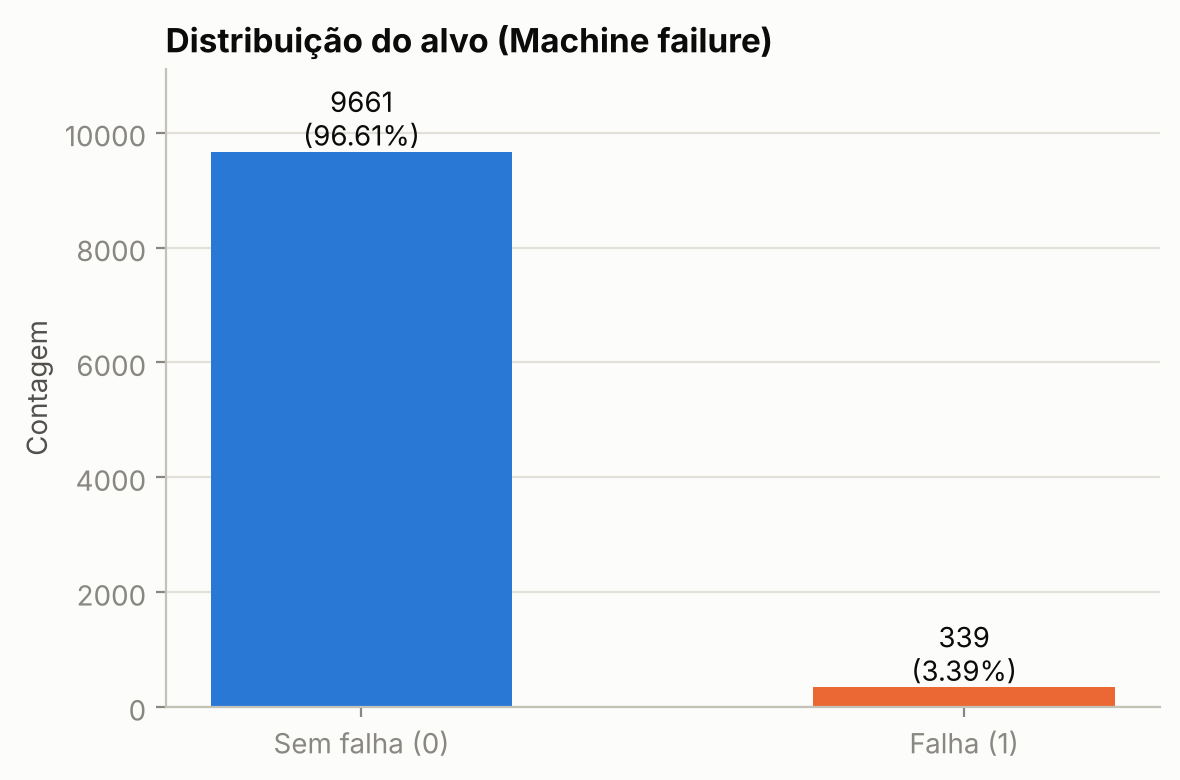

Taxa de falha: 3.39%  |  razão sem falha : falha ≈ 28 : 1
Acurácia de um modelo que SEMPRE prevê 'sem falha': 96.61%


In [8]:
vc = df["machine_failure"].value_counts().sort_index()
taxa_falha = df["machine_failure"].mean()

fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(["Sem falha (0)", "Falha (1)"], vc.values, color=[AZUL, LARANJA], width=0.5)
for b, v in zip(barras, vc.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f"{v}\n({v/len(df):.2%})", ha="center", va="bottom")
ax.set_ylim(0, vc.max() * 1.15); ax.set_ylabel("Contagem"); ax.set_title("Distribuição do alvo (Machine failure)")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

print(f"Taxa de falha: {taxa_falha:.2%}  |  razão sem falha : falha ≈ {vc[0]/vc[1]:.0f} : 1")
print(f"Acurácia de um modelo que SEMPRE prevê 'sem falha': {1 - taxa_falha:.2%}")

**Consequências para a modelagem**
- **Não usar acurácia** como métrica principal. Use *recall* da classe falha, *precisão*, **F1**, **PR-AUC** e a matriz de confusão.
- Usar **split estratificado** (`stratify=y`) para preservar a proporção de falhas em treino e teste.
- Considerar `class_weight="balanced"`, ajuste do limiar de decisão ou reamostragem (SMOTE etc.), **sempre aplicada só no treino**.
- Com apenas ~339 falhas no total, o conjunto de teste terá poucas dezenas de falhas, então as métricas variam bastante. Prefira validação cruzada estratificada.

## 6. Os modos de falha

`machine_failure` é o "OU" dos cinco modos. Quantos casos de cada um existem, eles se sobrepõem, e o rótulo é totalmente consistente com eles?

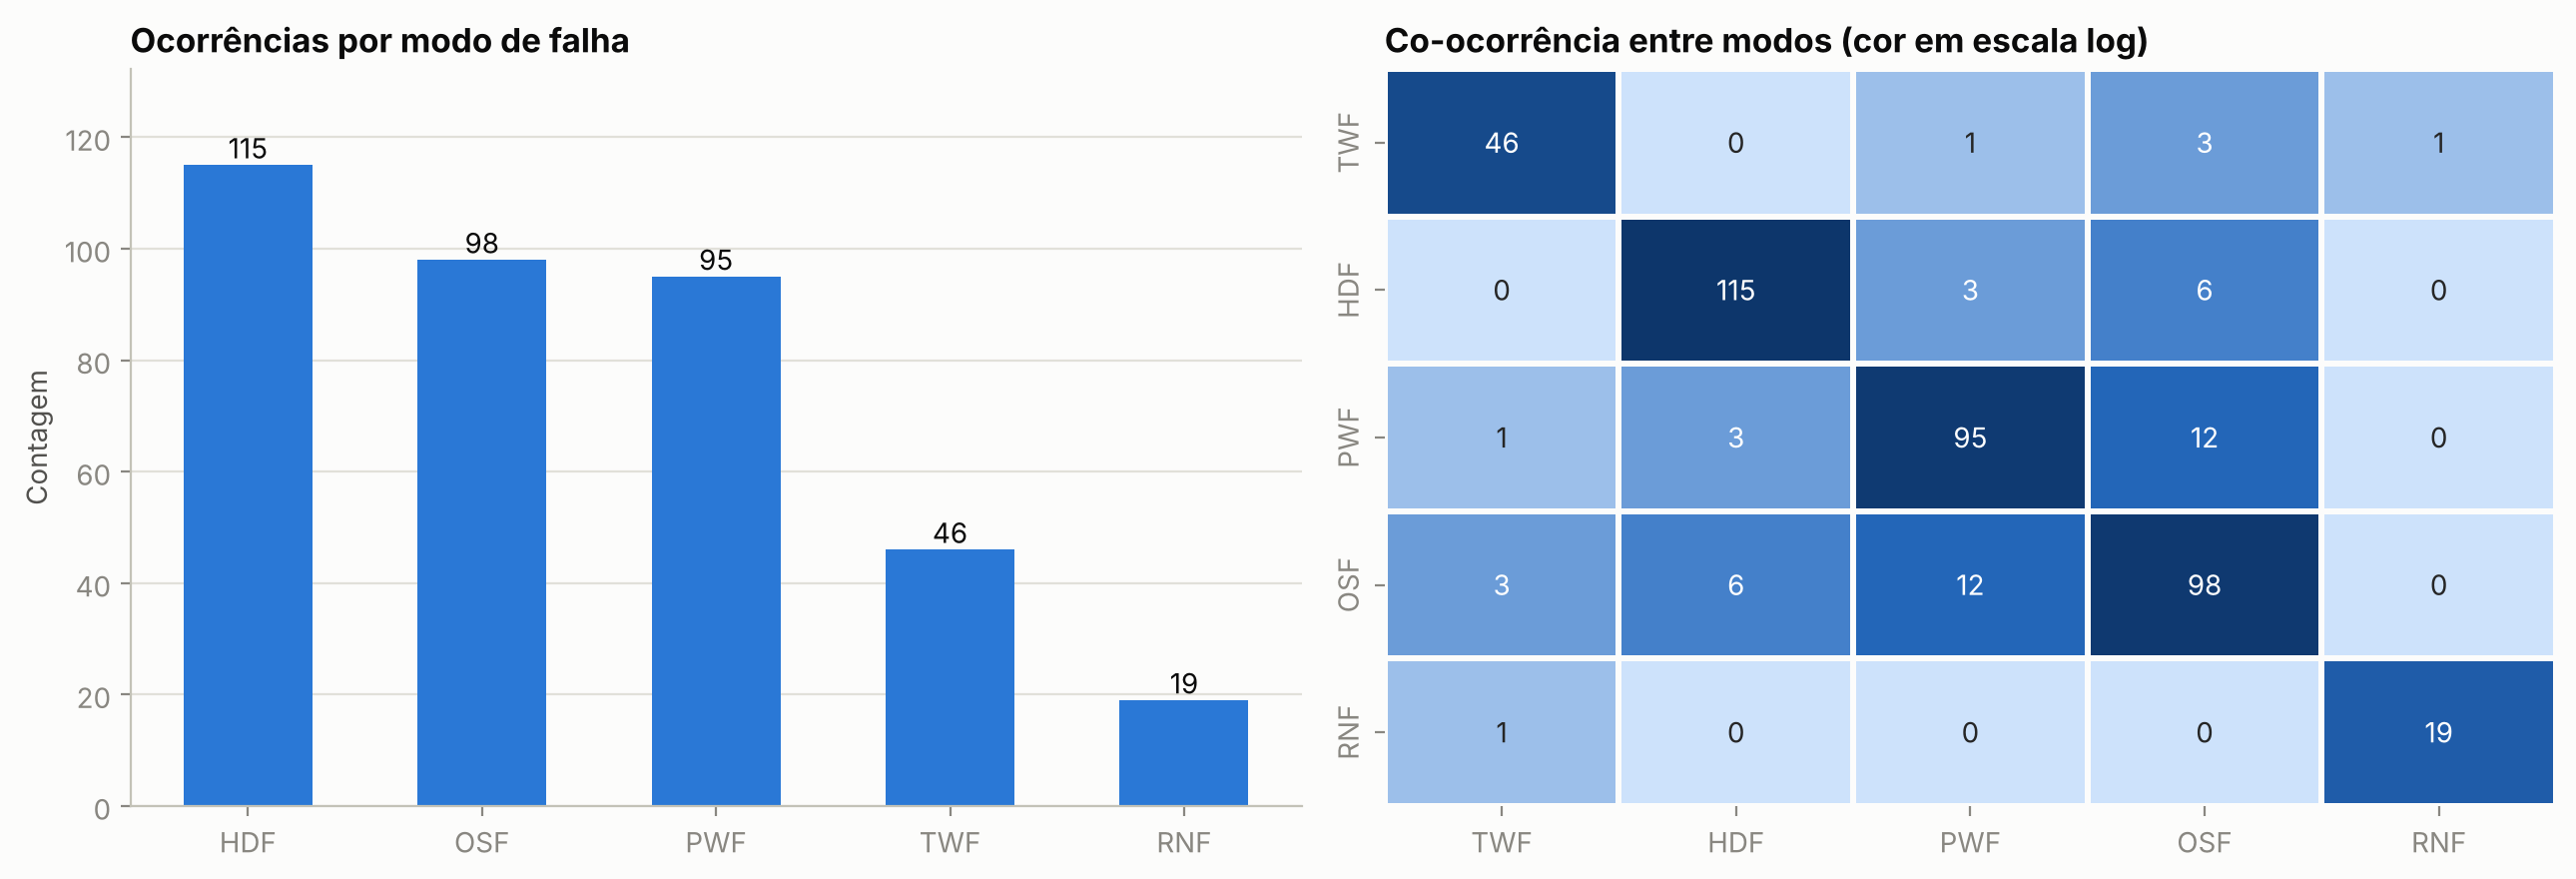

Nº de modos ativos por linha:


,linhas
n_modos,
0,9652
1,324
2,23
3,1


In [9]:
df["n_modos"] = df[MODOS].sum(axis=1)
contagem = df[MODOS].sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ax = axes[0]
ax.bar(contagem.index, contagem.values, color=AZUL, width=0.55)
for i, v in enumerate(contagem.values):
    ax.text(i, v, str(v), ha="center", va="bottom")
ax.set_ylim(0, contagem.max() * 1.15); ax.set_title("Ocorrências por modo de falha"); ax.set_ylabel("Contagem")
ax.grid(axis="x", visible=False)

ax = axes[1]
co = df[MODOS].T.dot(df[MODOS])
cmap_seq = LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#256abf", "#0d366b"])
sns.heatmap(np.log1p(co), annot=co, fmt="d", cmap=cmap_seq, cbar=False, linewidths=2, linecolor=SUPERFICIE, ax=ax)
ax.set_title("Co-ocorrência entre modos (cor em escala log)"); ax.grid(False)
plt.tight_layout(); plt.show()

print("Nº de modos ativos por linha:")
display(df["n_modos"].value_counts().sort_index().to_frame("linhas"))

In [10]:
sem_modo = df[(df.n_modos == 0) & (df.machine_failure == 1)]
modo_sem_falha = df[(df.n_modos > 0) & (df.machine_failure == 0)]

print(f"Linhas com machine_failure = 1 mas NENHUM modo ativo: {len(sem_modo)}")
print(f"Linhas com algum modo ativo mas machine_failure = 0 : {len(modo_sem_falha)}")
print("   modos nessas linhas:", modo_sem_falha[MODOS].sum()[lambda s: s > 0].to_dict())
print(f"RNF = 1 em {int(df.RNF.sum())} linhas, mas só {int(df.loc[df.RNF == 1, 'machine_failure'].sum())} delas tem machine_failure = 1")
print("\nAs linhas com falha sem modo explicativo:")
display(sem_modo[["udi", "type"] + NUM + ["machine_failure"] + MODOS])

Linhas com machine_failure = 1 mas NENHUM modo ativo: 9
Linhas com algum modo ativo mas machine_failure = 0 : 18
   modos nessas linhas: {'RNF': 18}
RNF = 1 em 19 linhas, mas só 1 delas tem machine_failure = 1

As linhas com falha sem modo explicativo:


,udi,type,air_temp,process_temp,rpm,torque,tool_wear,machine_failure,TWF,HDF,PWF,OSF,RNF
1437,1438,H,298.8,309.9,1439,45.2,40,1,0,0,0,0,0
2749,2750,M,299.7,309.2,1685,28.9,179,1,0,0,0,0,0
4044,4045,M,301.9,310.9,1419,47.7,20,1,0,0,0,0,0
4684,4685,M,303.6,311.8,1421,44.8,101,1,0,0,0,0,0
5536,5537,M,302.3,311.8,1363,54.0,119,1,0,0,0,0,0
5941,5942,L,300.6,310.7,1438,48.5,78,1,0,0,0,0,0
6478,6479,L,300.5,309.8,1663,29.1,145,1,0,0,0,0,0
8506,8507,L,298.4,309.6,1710,27.3,163,1,0,0,0,0,0
9015,9016,L,297.2,308.1,1431,49.7,210,1,0,0,0,0,0


**O que descobrimos**
- Os modos mais comuns são **HDF** (115), **OSF** (98) e **PWF** (95). **TWF** (46) é menos frequente e **RNF** (19) é ruído puro.
- As falhas **se sobrepõem pouco**: 24 linhas têm 2 ou mais modos ao mesmo tempo, então um modelo precisa lidar com múltiplas causas.
- **Rótulo inconsistente em 27 linhas** (0,27% do total):
  - **9 linhas** têm falha, mas nenhum modo ativo. Não há explicação nos dados.
  - **18 linhas** têm `RNF = 1` e `machine_failure = 0`: o ruído aleatório foi registrado no modo, mas **não** propagado para o alvo.
- O **RNF é imprevisível por construção** (é um sorteio de 0,1%). Isso impõe um **teto de desempenho**: nenhum modelo vai acertar 100% das falhas, e isso não é bug do modelo.

## 7. Variáveis derivadas e validação das regras físicas

Três dos modos dependem de **combinações** das variáveis brutas, não de uma variável sozinha:

- **ΔT** = temperatura do processo − temperatura do ar (HDF)
- **Potência [W]** = torque × rotação × 2π / 60 (PWF)
- **Desgaste × torque** (OSF), com limite que depende do Type

Vamos recalcular essas regras e comparar com as colunas `HDF`, `PWF` e `OSF` do CSV.

In [11]:
df["temp_diff"] = df.process_temp - df.air_temp
df["power_w"] = df.torque * df.rpm * 2 * np.pi / 60          # rpm -> rad/s
df["wear_x_torque"] = df.tool_wear * df.torque
limite_osf = df["type"].map({"L": 11000, "M": 12000, "H": 13000})

regras = {
    "HDF": (df.temp_diff < 8.6) & (df.rpm < 1380),
    "PWF": (df.power_w < 3500) | (df.power_w > 9000),
    "OSF": df.wear_x_torque > limite_osf,
}
linhas = []
for modo, r in regras.items():
    linhas.append({"modo": modo, "regra dispara": int(r.sum()), "flag no CSV": int(df[modo].sum()),
                   "linhas coincidentes (%)": round((r.astype(int) == df[modo]).mean() * 100, 2)})
display(pd.DataFrame(linhas).set_index("modo"))

twf = df[df.TWF == 1].tool_wear
print(f"TWF: desgaste das {len(twf)} linhas com falha vai de {twf.min()} a {twf.max()} min (mediana {twf.median():.0f}).")
print(f"Linhas com desgaste >= 200 min: {(df.tool_wear >= 200).sum()}, das quais {int(df.loc[df.tool_wear >= 200, 'TWF'].sum())} são TWF.")

,regra dispara,flag no CSV,linhas coincidentes (%)
modo,,,
HDF,115,115,100.0
PWF,95,95,100.0
OSF,98,98,100.0


TWF: desgaste das 46 linhas com falha vai de 198 a 253 min (mediana 214).
Linhas com desgaste >= 200 min: 801, das quais 45 são TWF.


**Resultado:** as regras de HDF, PWF e OSF reproduzem **100%** dos rótulos do CSV. Ou seja, **o alvo é uma função determinística das variáveis**, com exceção do TWF (o limite é sorteado entre 200 e 240 min) e do RNF (aleatório).

**Por que isso importa para o nosso projeto (modelo + Shapash):**
- Um modelo bom deve "redescobrir" essas regras. Se o Shapash mostrar que o modelo usa torque, rotação, desgaste e ΔT de forma coerente com as regras, isso é uma **validação da explicação**, pois temos o gabarito.
- Modelos de árvore enxergam bem limiares em variáveis individuais, mas têm mais dificuldade com **produtos** (potência = torque × rotação). Adicionar `power_w`, `temp_diff` e `wear_x_torque` como *features* pode melhorar muito o desempenho. É uma decisão de projeto: usar as features derivadas (mais desempenho, menos "descoberta") ou só as brutas (o modelo precisa aprender as interações).

## 8. Análise bivariada

### 8.1 Variáveis × falha

Comparação das distribuições entre linhas **sem falha** (azul) e **com falha** (laranja). As quatro últimas são as variáveis derivadas da seção 7.

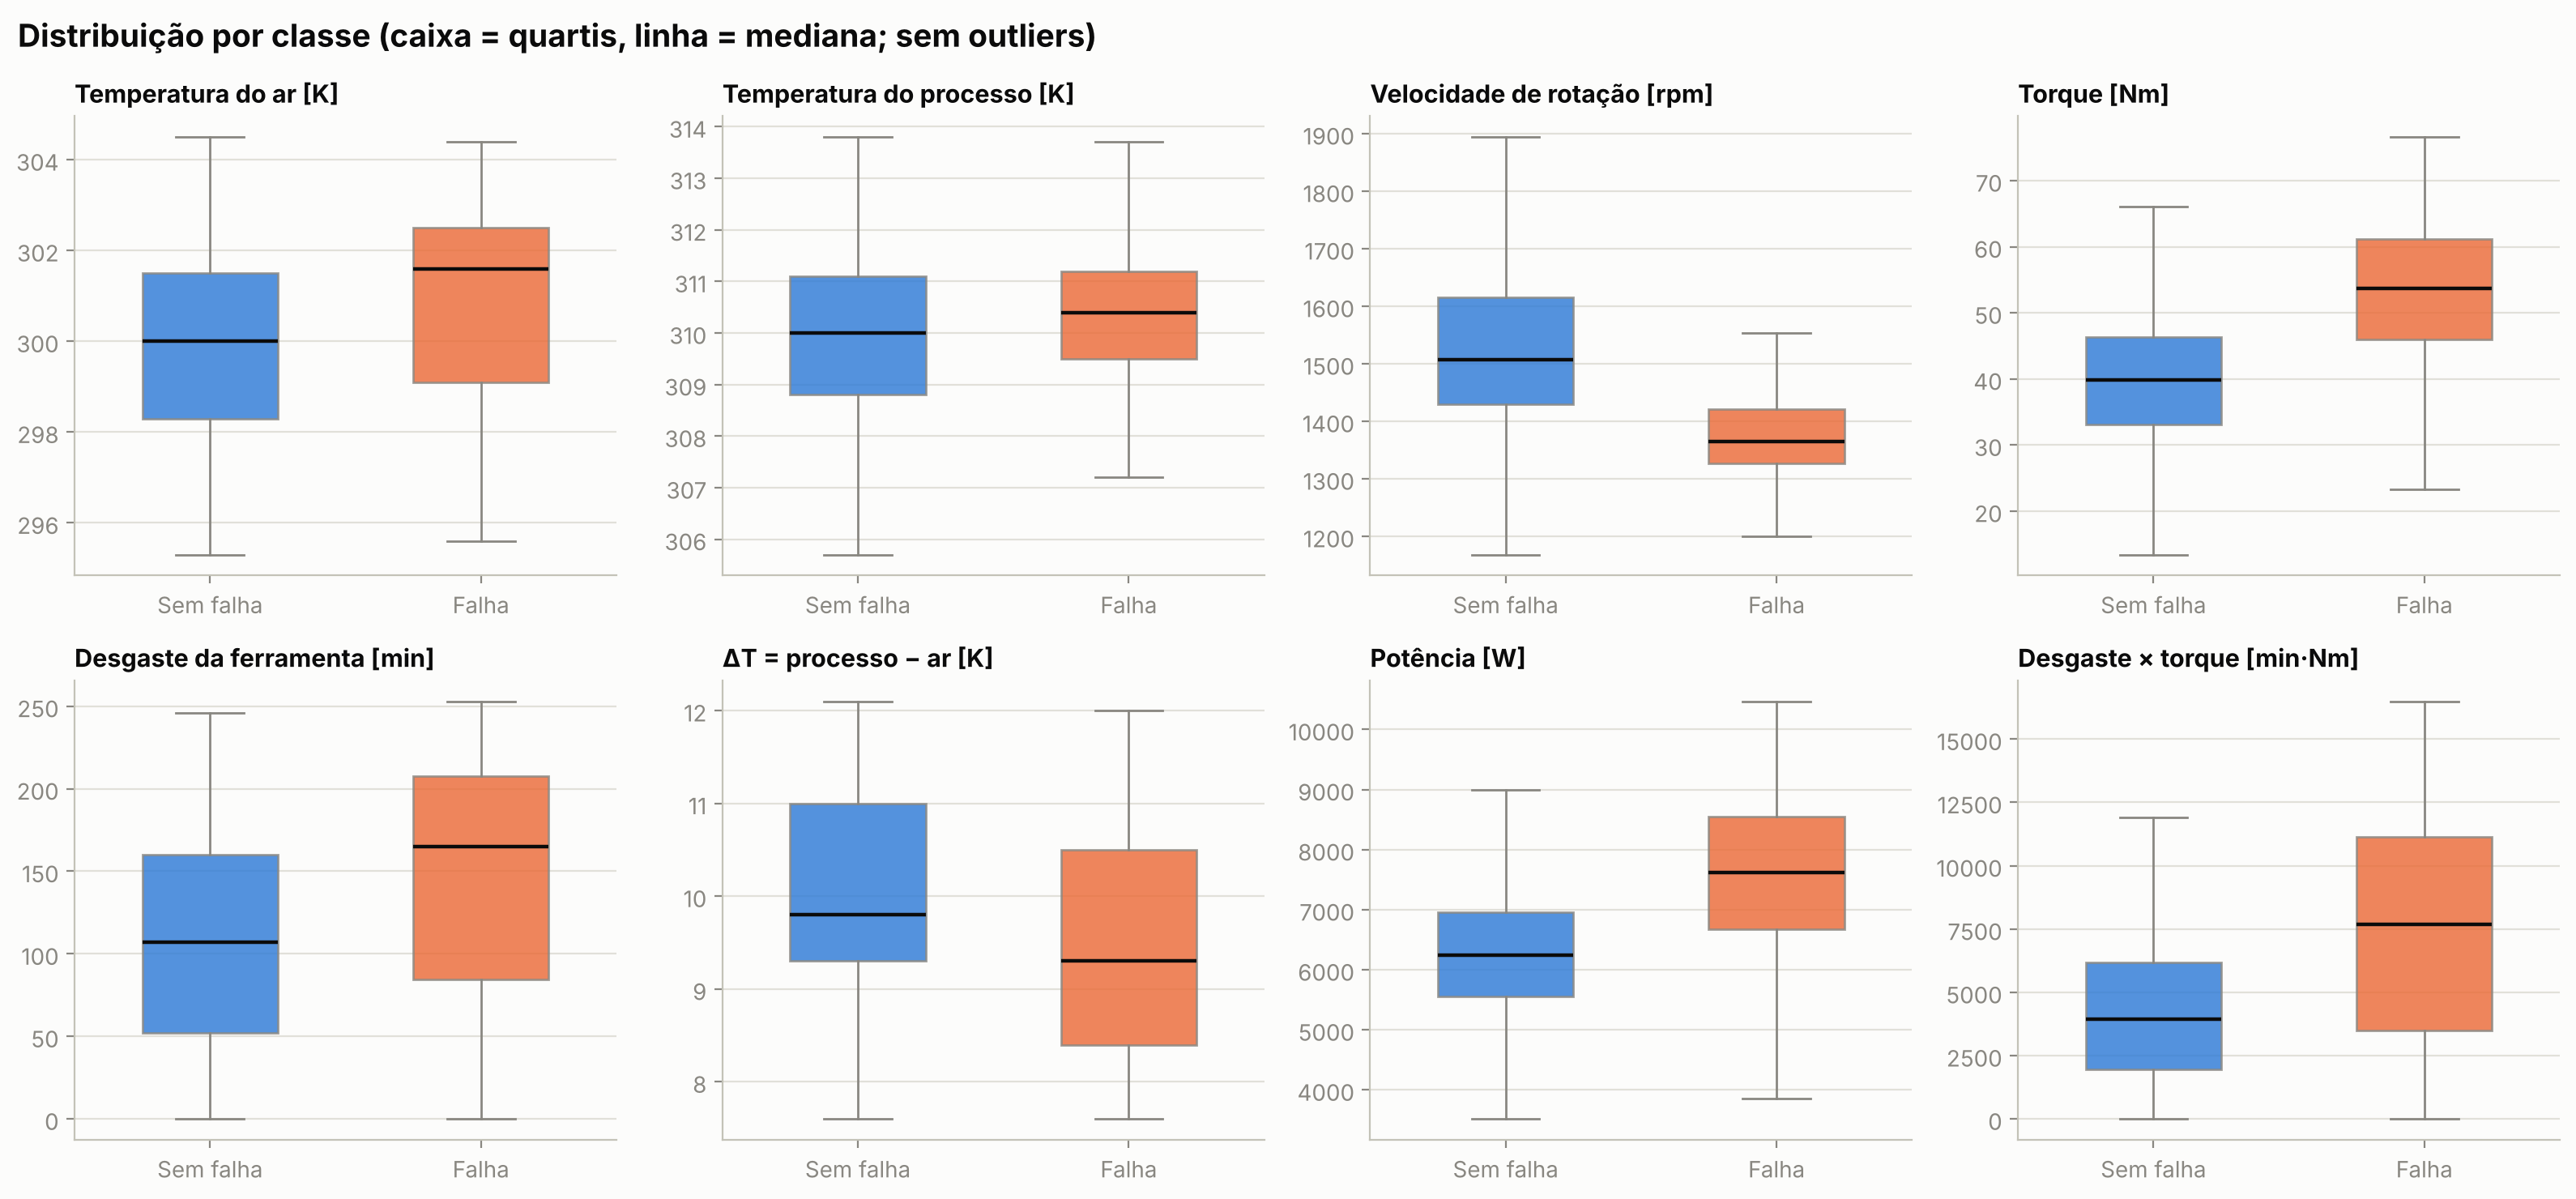

In [12]:
feats = ["air_temp", "process_temp", "rpm", "torque", "tool_wear", "temp_diff", "power_w", "wear_x_torque"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for ax, col in zip(axes.flat, feats):
    dados = [df.loc[df.machine_failure == 0, col], df.loc[df.machine_failure == 1, col]]
    bp = ax.boxplot(dados, patch_artist=True, widths=0.5, showfliers=False,
                    medianprops=dict(color=TEXTO, lw=1.6), whiskerprops=dict(color=MUDO), capprops=dict(color=MUDO))
    for patch, c in zip(bp["boxes"], [AZUL, LARANJA]):
        patch.set_facecolor(c); patch.set_alpha(0.8); patch.set_edgecolor(MUDO)
    ax.set_xticks([1, 2]); ax.set_xticklabels(["Sem falha", "Falha"]); ax.set_title(LABELS[col], fontsize=11)
    ax.grid(axis="x", visible=False)
fig.suptitle("Distribuição por classe (caixa = quartis, linha = mediana; sem outliers)", x=0.01, ha="left", fontsize=14, fontweight="bold")
plt.tight_layout(); plt.show()

**Leitura**
- Em média, linhas com falha têm **torque mais alto**, **rotação mais baixa** e **mais desgaste** que as sem falha.
- A **temperatura do ar** é um pouco mais alta nas falhas (mediana ≈ 301,6 K contra 300,0 K) e a do processo quase não muda. O **ΔT** é menor nas falhas (≈ 9,3 K contra 9,8 K), efeito do HDF, mas a diferença de mediana é modesta porque o HDF só ocorre quando ΔT baixo e rotação baixa acontecem **juntos**.
- `wear_x_torque` e `power_w` separam as classes melhor que as variáveis brutas isoladas, o que reforça o argumento a favor das derivadas na seção 7.
- Cuidado: as caixas escondem que cada modo de falha acontece numa região diferente. A seção 9 mostra isso de forma mais clara.

### 8.2 Correlações

*Lembrete:* correlação linear só enxerga relações "em linha reta" e **não detecta** regras de limiar (como "falha se rotação < 1380 e ΔT < 8,6").

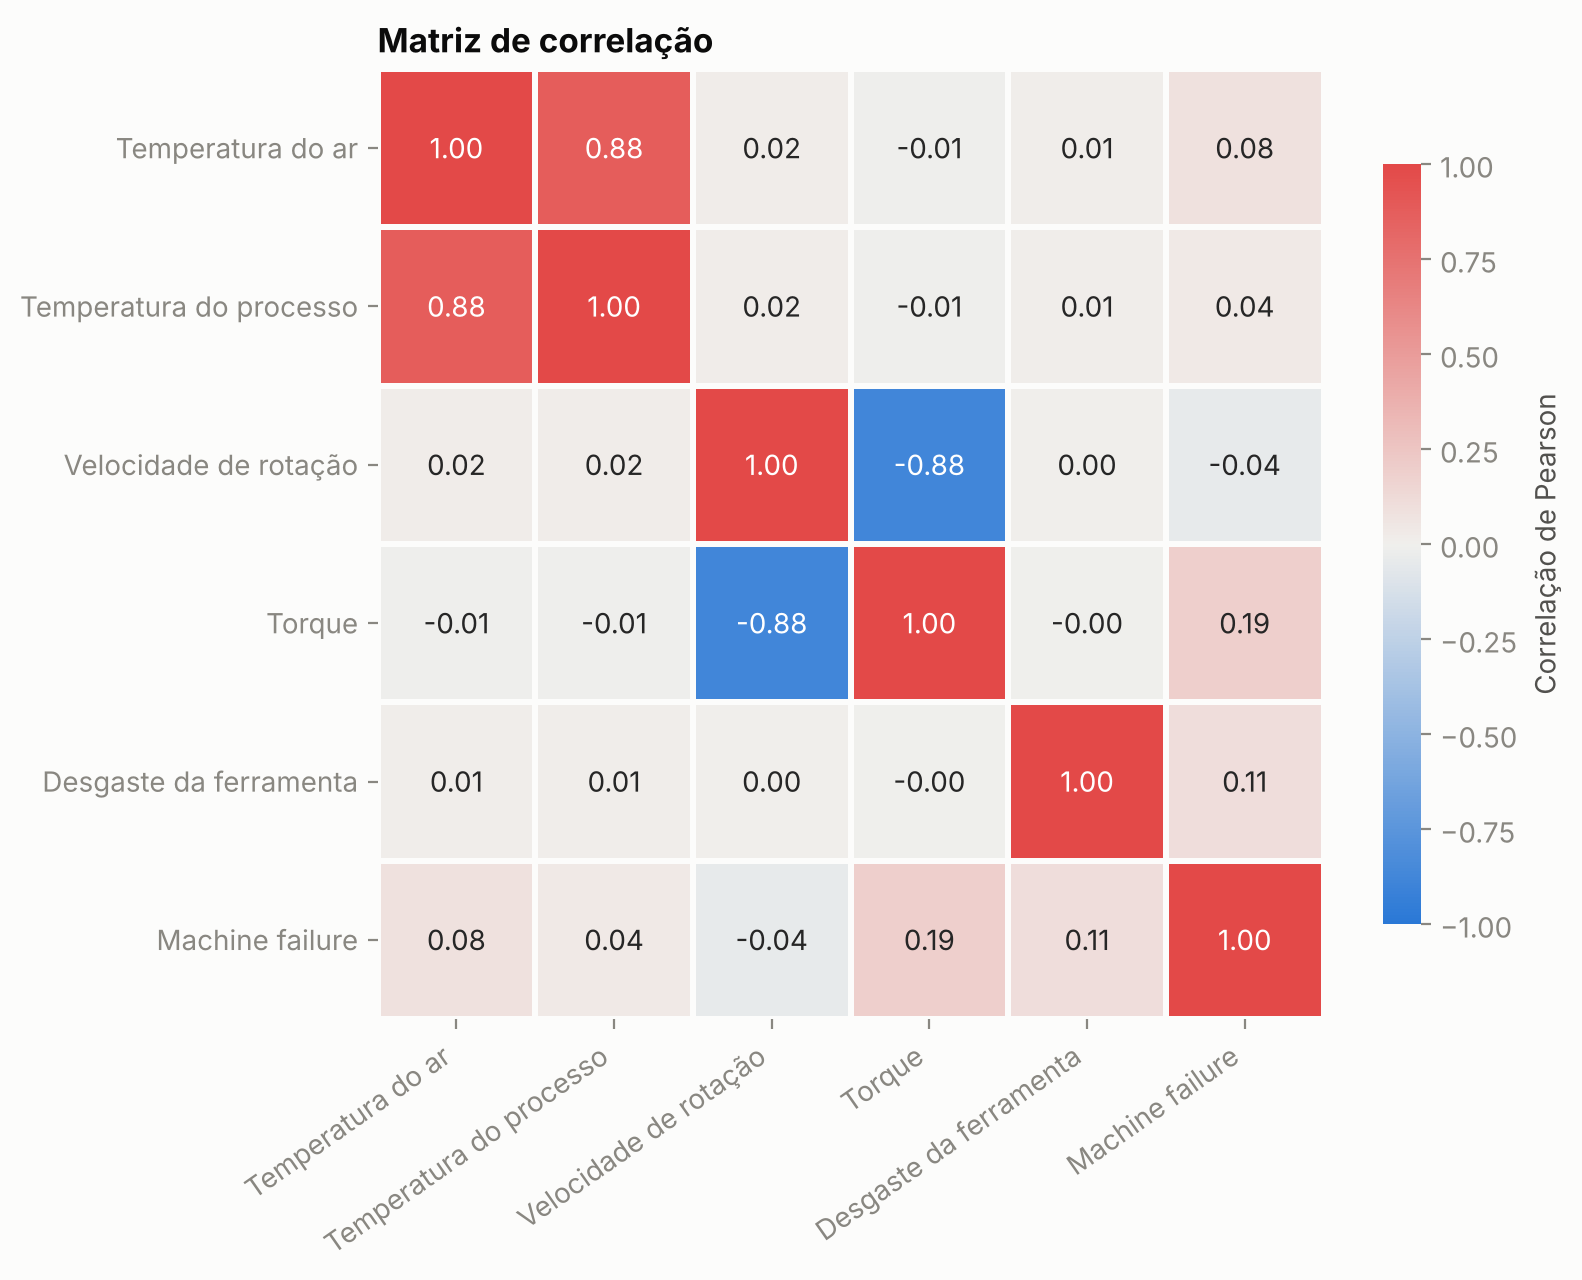

In [13]:
cols_corr = NUM + ["machine_failure"]
corr = df[cols_corr].corr()
nomes = [LABELS.get(c, "Machine failure").split(" [")[0] for c in cols_corr]
cmap_div = LinearSegmentedColormap.from_list("div", ["#2a78d6", "#f0efec", "#e34948"])

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap=cmap_div, vmin=-1, vmax=1, center=0,
            xticklabels=nomes, yticklabels=nomes, linewidths=2, linecolor=SUPERFICIE,
            cbar_kws={"label": "Correlação de Pearson", "shrink": 0.8}, ax=ax)
ax.set_title("Matriz de correlação"); ax.grid(False)
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()

**Leitura**
- **Temperatura do ar × temperatura do processo: ≈ +0,88.** A temperatura do processo foi gerada como "ar + 10 K + ruído", então elas andam juntas.
- **Rotação × torque: ≈ −0,88.** Potência quase constante: se um sobe, o outro cai.
- A correlação de **cada variável com a falha é baixa** (nenhuma passa de ~0,2). Isso **não** quer dizer que as variáveis sejam inúteis. A relação é por regras de limiar e interações, que a correlação linear não captura.
- **Impacto no Shapash/SHAP:** com variáveis tão correlacionadas, a importância se **divide** entre elas (rotação e torque "dividem o crédito"). Ao interpretar o gráfico de importância, lembrar disso para não concluir que uma delas é irrelevante.

### 8.3 Taxa de falha por Type e por faixa de desgaste

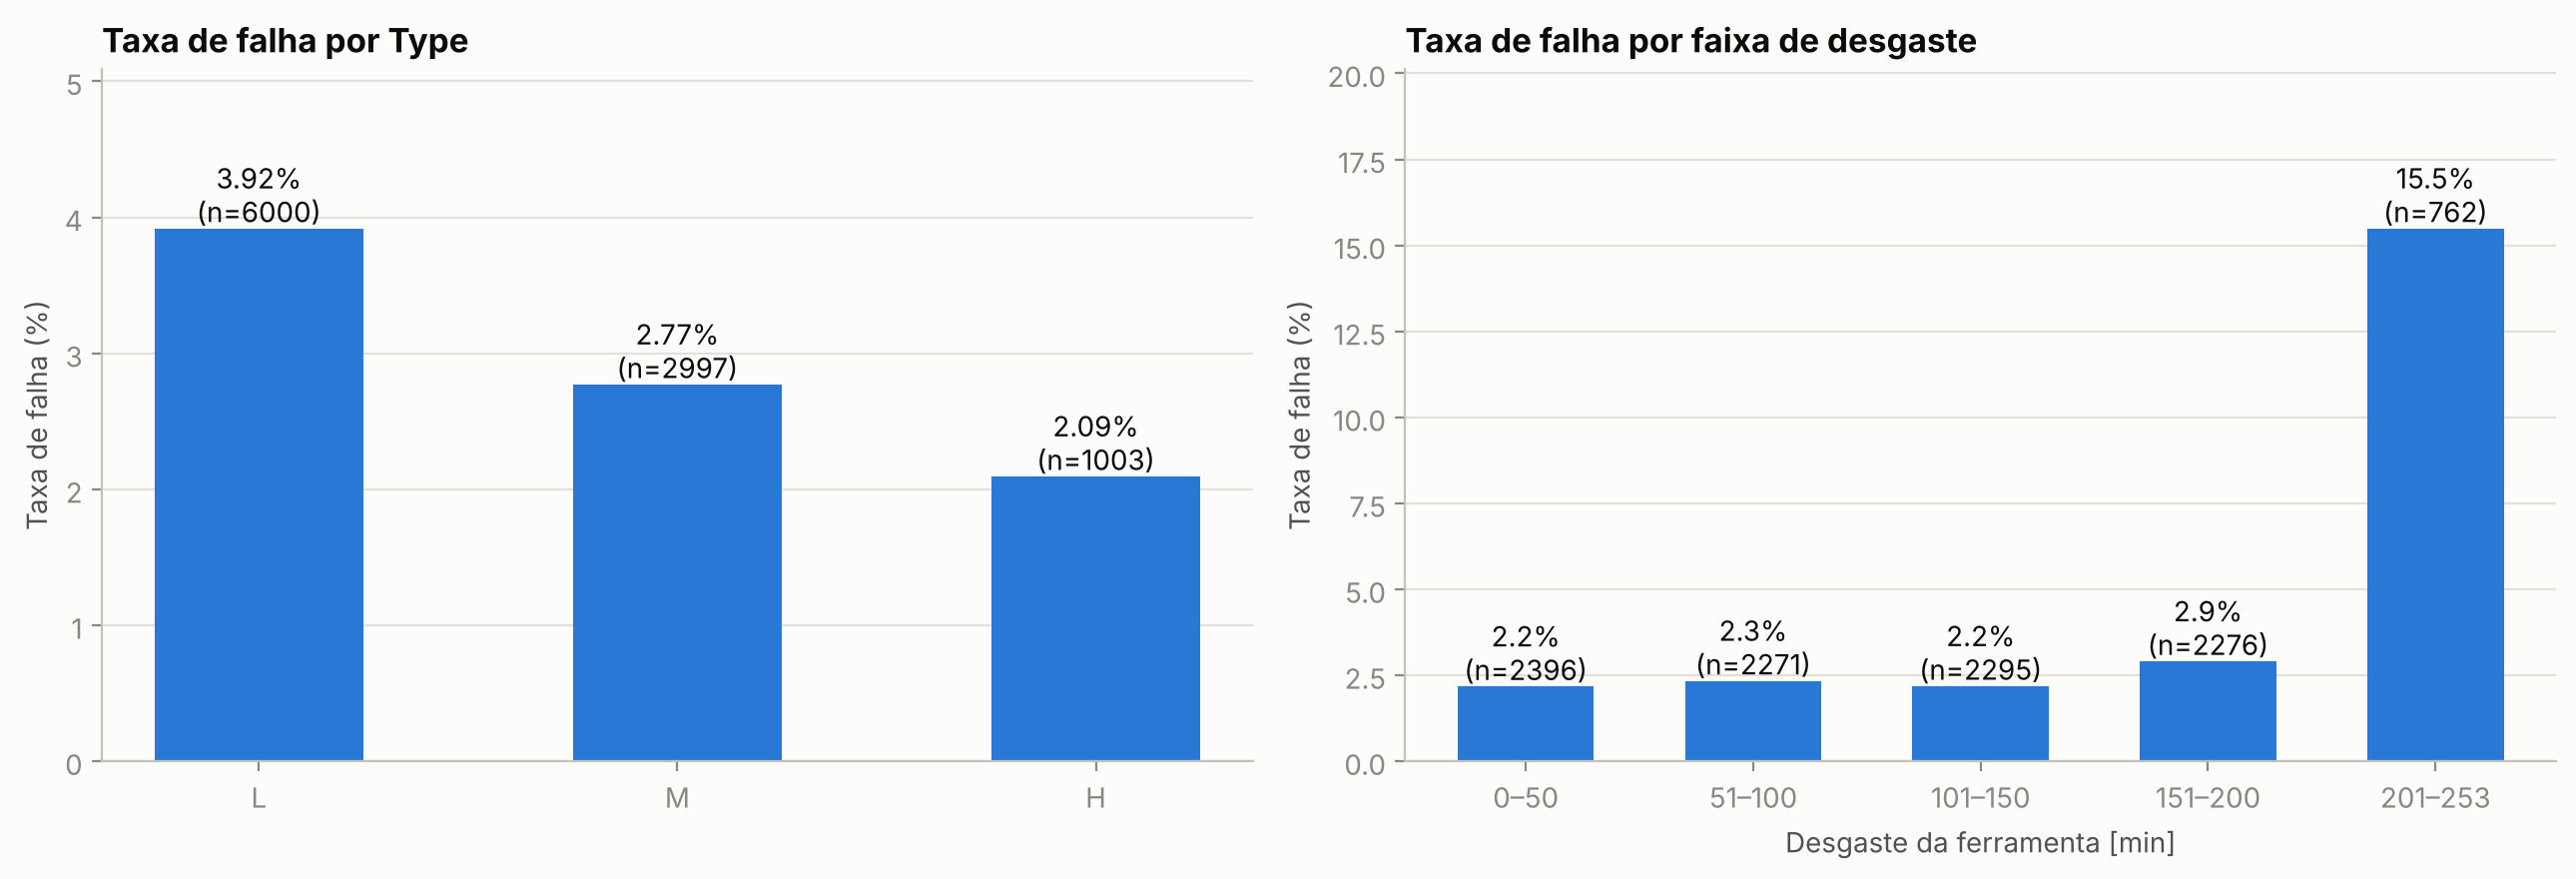

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

ax = axes[0]
por_tipo = df.groupby("type")["machine_failure"].agg(["mean", "size"]).reindex(["L", "M", "H"])
ax.bar(por_tipo.index, por_tipo["mean"] * 100, color=AZUL, width=0.5)
for i, (m, n) in enumerate(zip(por_tipo["mean"], por_tipo["size"])):
    ax.text(i, m * 100, f"{m:.2%}\n(n={n})", ha="center", va="bottom")
ax.set_ylim(0, por_tipo["mean"].max() * 100 * 1.3); ax.set_ylabel("Taxa de falha (%)")
ax.set_title("Taxa de falha por Type"); ax.grid(axis="x", visible=False)

ax = axes[1]
faixas = pd.cut(df.tool_wear, bins=[-1, 50, 100, 150, 200, 260],
                labels=["0–50", "51–100", "101–150", "151–200", "201–253"])
por_faixa = df.groupby(faixas, observed=True)["machine_failure"].agg(["mean", "size"])
ax.bar(por_faixa.index.astype(str), por_faixa["mean"] * 100, color=AZUL, width=0.6)
for i, (m, n) in enumerate(zip(por_faixa["mean"], por_faixa["size"])):
    ax.text(i, m * 100, f"{m:.1%}\n(n={n})", ha="center", va="bottom")
ax.set_ylim(0, por_faixa["mean"].max() * 100 * 1.3); ax.set_ylabel("Taxa de falha (%)")
ax.set_xlabel("Desgaste da ferramenta [min]"); ax.set_title("Taxa de falha por faixa de desgaste")
ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

**Leitura**
- **Type:** a taxa de falha cai de L (≈ 3,9%) para M (≈ 2,8%) e H (≈ 2,1%). Ou seja, produtos de maior qualidade falham menos, o que é plausível, pois o limite do OSF é maior para H. Mas H tem só ~1000 linhas, então a diferença deve ser lida com cautela.
- **Desgaste:** a taxa de falha fica estável, em torno de 2–3%, até 200 min e **salta para ~15% acima de 200 min**, faixa em que entram o TWF (a ferramenta passa a poder quebrar) e o OSF com mais facilidade.

## 9. Relações físicas em gráficos

Aqui os modos de falha aparecem "desenhados". Cada painel mostra uma regra de falha como uma **fronteira** (linhas tracejadas cinza), com as falhas (laranja) concentradas fora da região segura.

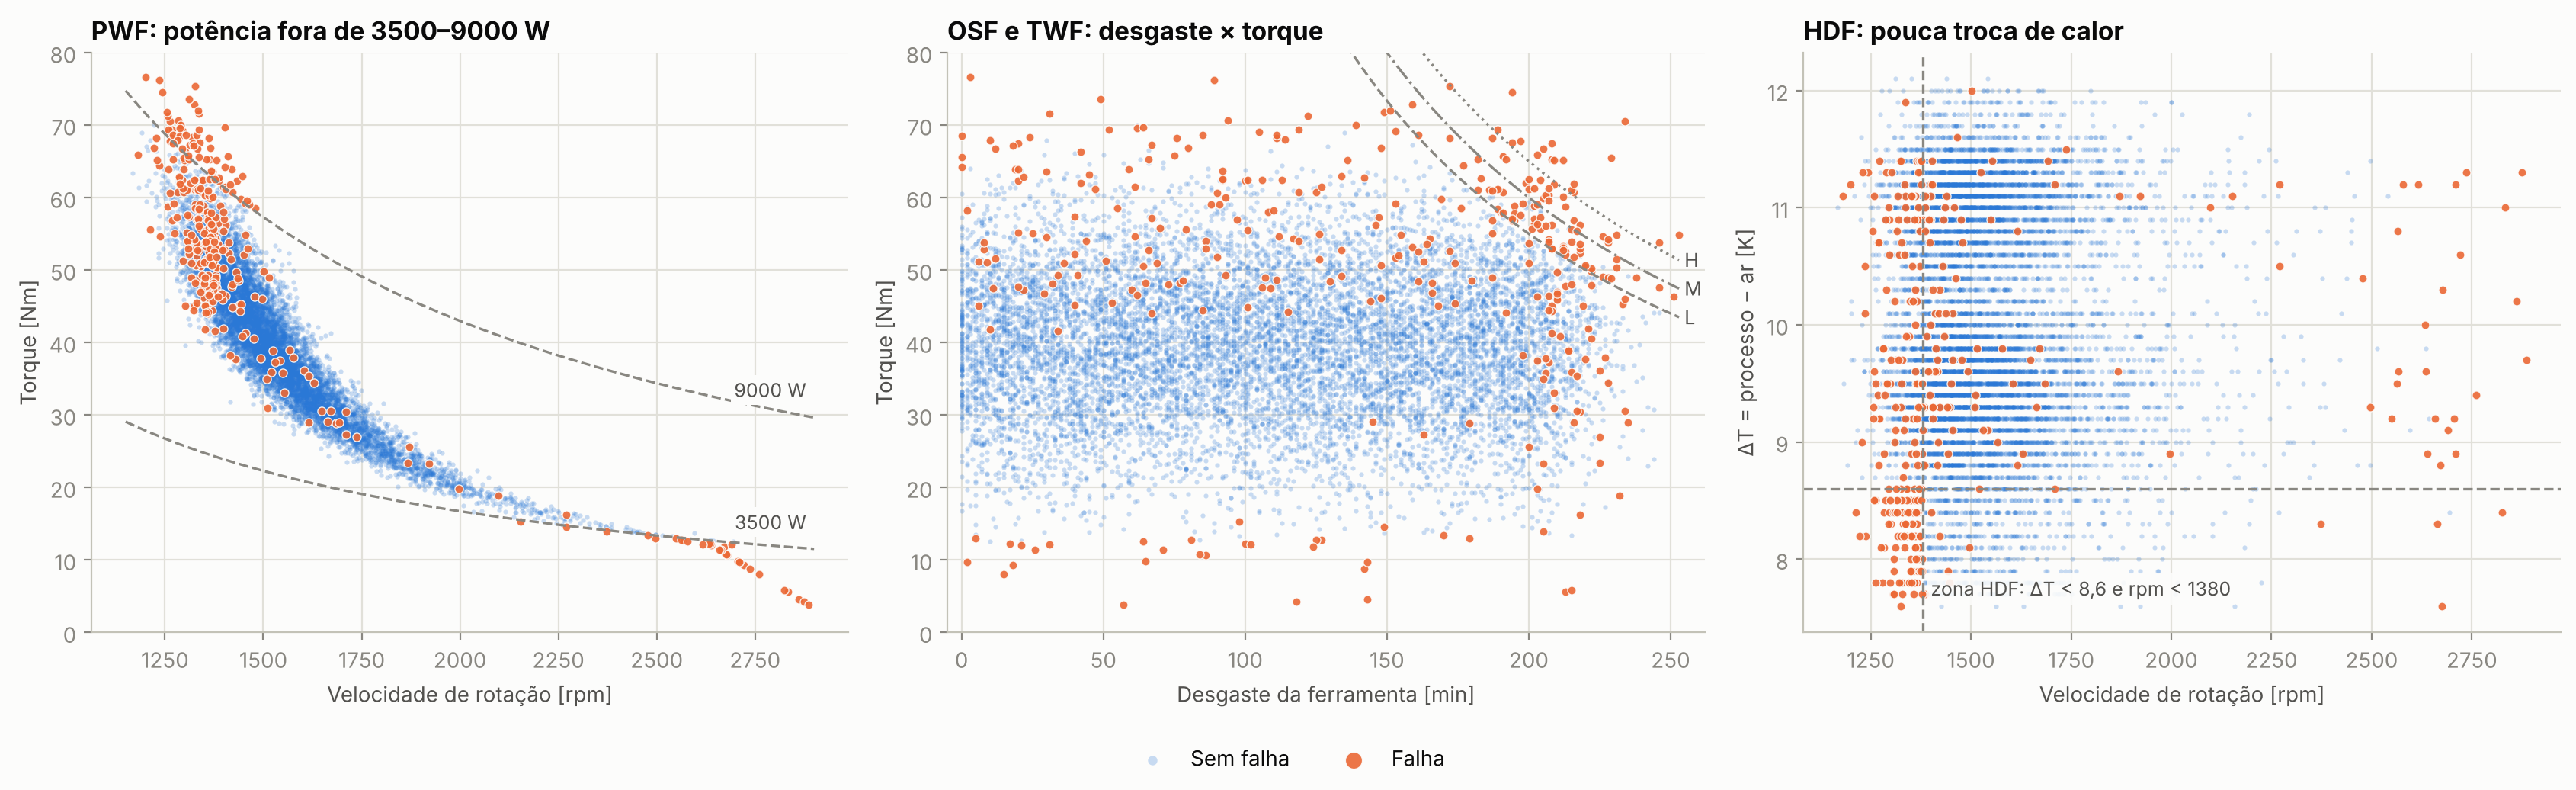

In [15]:
nf = df[df.machine_failure == 0]; f = df[df.machine_failure == 1]
def pontos(ax, x, y):
    ax.scatter(nf[x], nf[y], s=5, color=AZUL, alpha=0.25, linewidths=0, label="Sem falha")
    ax.scatter(f[x], f[y], s=16, color=LARANJA, alpha=0.9, edgecolor=SUPERFICIE, linewidths=0.5, label="Falha")

fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))

# (a) Torque x rotação -> PWF
ax = axes[0]; pontos(ax, "rpm", "torque")
r = np.linspace(1150, 2900, 300)
for P in (3500, 9000):
    ax.plot(r, P * 60 / (2 * np.pi * r), color=MUDO, lw=1.2, ls="--")
    ax.text(2880, P * 60 / (2 * np.pi * 2880) + 2, f"{P} W", ha="right", va="bottom", color=TEXTO2, fontsize=9,
            bbox=dict(facecolor=SUPERFICIE, edgecolor="none", pad=1.5))
ax.set_ylim(0, 80); ax.set_xlabel(LABELS["rpm"]); ax.set_ylabel(LABELS["torque"])
ax.set_title("PWF: potência fora de 3500–9000 W")

# (b) Desgaste x torque -> OSF
ax = axes[1]; pontos(ax, "tool_wear", "torque")
w = np.linspace(100, 253, 200)
for lim, nome, estilo in [(11000, "L", "--"), (12000, "M", "-."), (13000, "H", ":")]:
    ax.plot(w, lim / w, color=MUDO, lw=1.2, ls=estilo)
    ax.text(253, lim / 253, f" {nome}", va="center", color=TEXTO2, fontsize=9)
ax.set_ylim(0, 80); ax.set_xlim(-5, 262)
ax.set_xlabel(LABELS["tool_wear"]); ax.set_ylabel(LABELS["torque"])
ax.set_title("OSF e TWF: desgaste × torque")

# (c) Rotação x ΔT -> HDF
ax = axes[2]; pontos(ax, "rpm", "temp_diff")
ax.axvline(1380, color=MUDO, lw=1.2, ls="--"); ax.axhline(8.6, color=MUDO, lw=1.2, ls="--")
ax.text(1400, df.temp_diff.min() + 0.05, "zona HDF: ΔT < 8,6 e rpm < 1380", color=TEXTO2, fontsize=9, va="bottom",
        bbox=dict(facecolor=SUPERFICIE, edgecolor="none", alpha=0.9, pad=2))
ax.set_xlabel(LABELS["rpm"]); ax.set_ylabel(LABELS["temp_diff"])
ax.set_title("HDF: pouca troca de calor")

h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc="lower center", ncol=2, markerscale=2, fontsize=10)
plt.tight_layout(rect=[0, 0.07, 1, 1]); plt.show()

**Leitura**
- **(a)** Os dados formam uma "nuvem em hipérbole" (torque ≈ potência / rotação). As falhas por potência ficam **fora das curvas de 3500 W e 9000 W**: torque alto com rotação baixa, ou rotação alta com torque baixo.
- **(b)** Falhas por sobrecarga aparecem **acima das curvas** (desgaste × torque grande), com limite diferente para cada Type. Os pontos de falha à direita, com desgaste alto mas torque normal, são, em geral, TWF.
- **(c)** O HDF é um retângulo no canto inferior esquerdo: rotação baixa **e** ΔT pequeno ao mesmo tempo. Nenhuma das duas condições sozinha causa falha, e por isso a correlação linear não capturava isso.

Estes três gráficos são um bom "gabarito visual" para comparar com os gráficos do Shapash depois.

## 10. Armadilhas para a modelagem

**1. Vazamento de dados (*data leakage*)**
`TWF`, `HDF`, `PWF`, `OSF` e `RNF` são os componentes do alvo. Usá-los como *features* para prever `machine_failure` é como **estudar com o gabarito da prova na mesa**: o modelo acerta quase 100%, sem aprender nada de útil. O código abaixo mostra isso.

In [16]:
ou_dos_modos = (df[MODOS].sum(axis=1) > 0).astype(int)
conc = (ou_dos_modos == df.machine_failure).mean()
print(f"'OU' dos 5 modos reproduz machine_failure em {conc:.2%} das linhas ({int((ou_dos_modos != df.machine_failure).sum())} divergências).")
print("-> Um modelo com esses 5 modos como features teria ~99,7% de acerto 'de graça'. Remova-os de X.")

'OU' dos 5 modos reproduz machine_failure em 99.73% das linhas (27 divergências).
-> Um modelo com esses 5 modos como features teria ~99,7% de acerto 'de graça'. Remova-os de X.


**2. Colunas a descartar de X:** `udi`, `product_id` (identificadores), e os cinco modos de falha. Se quiserem usar `type`, codifiquem (one-hot ou ordinal L < M < H).

**3. Features derivadas: uma decisão de projeto.** `temp_diff`, `power_w` e `wear_x_torque` são conhecimento de domínio legítimo, mas são exatamente as fórmulas dos modos de falha. Definam como grupo se serão usadas e, se forem, comparem os resultados com e sem elas.

**4. Multicolinearidade.** Ar × processo (0,88) e rotação × torque (−0,88). Para modelos de árvore não é problema de desempenho, mas **distorce a interpretação** (importância dividida entre variáveis).

**5. Métrica errada.** Acurácia engana (seção 5). Usem recall, precisão, F1 e PR-AUC.

**6. Divisão treino/teste.** Estratificada e **decidida conscientemente** quanto à ordem temporal (seção 4).

**7. Ruído irredutível.** RNF e as 27 linhas inconsistentes limitam o desempenho máximo. Decidam se mantêm ou removem as inconsistentes e registrem a decisão.

**8. Dados sintéticos.** Conclusões valem para o simulador. Para o protótipo isso é ótimo (temos o gabarito), mas não afirmem que o modelo "funciona em máquinas reais".

## 11. Conclusões e próximos passos

**Resumo do dataset**
- 10.000 linhas, 5 variáveis numéricas + 1 categórica (`type`), sem nulos nem duplicatas.
- Alvo binário **muito desbalanceado**: 339 falhas (3,39%).
- Cinco modos de falha, três deles (HDF, PWF, OSF) **totalmente determinísticos** a partir das variáveis; TWF parcialmente; RNF é aleatório.
- Temperaturas e desgaste têm **dependência temporal**; rotação e torque, não.
- Há pequenas **divergências** entre o documento descritivo e o CSV, e 27 linhas com rótulo inconsistente.

**Sugestão de próximos passos para o grupo**
1. Fixar o **protocolo de avaliação**: métricas (recall, F1, PR-AUC), split estratificado, validação cruzada.
2. Decidir sobre **features derivadas** e sobre as **27 linhas inconsistentes**.
3. Treinar um *baseline* simples (regressão logística / árvore) e depois um modelo mais forte (Random Forest, XGBoost ou LightGBM).
4. Integrar o modelo ao **Shapash** e comparar as explicações com as regras físicas das seções 7 e 9 (o gabarito).
5. Só então ligar ao **frontend**.

---
*Referência: S. Matzka, "Explainable Artificial Intelligence for Predictive Maintenance Applications", 2020 (conferência AI4I). Dataset: UCI Machine Learning Repository, "AI4I 2020 Predictive Maintenance Dataset".*